# Impuestos y cotizaciones sobre el salario medio

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "cuna-fiscal-trabajo"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Impuestos y cotizaciones sobre el salario medio"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del coste laboral"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La *cuña fiscal* sobre el trabajo: qué parte de lo que cuesta un trabajador a la empresa se paga en impuesto sobre la renta (en España, el IRPF) y en cotizaciones sociales del trabajador y de la empresa, descontadas las prestaciones monetarias que recibe. El caso es el de un trabajador soltero y sin hijos que cobra el salario medio de su país (100 %), calculado por la OCDE en *Taxing Wages*. El coste laboral es el salario bruto más las cotizaciones a cargo de la empresa.

**Cómo se lee.** Un valor de 40 significa que, de cada 100 euros que cuesta el trabajador a la empresa, 40 se pagan en impuesto sobre la renta y cotizaciones (descontadas las prestaciones) y 60 llegan al trabajador como salario neto.

**Limitaciones.**
- Es un caso tipo calculado con las normas de cada año, no la media de lo que pagan los asalariados: solo tiene en cuenta las deducciones de aplicación general, no las ligadas a gastos o circunstancias personales (p. ej. la vivienda).
- No incluye otros impuestos que soporta el trabajador, como el IVA.
- El salario medio es el que estima la OCDE para los trabajadores a tiempo completo de cada país: se comparan situaciones equivalentes, no salarios iguales.
- En países con impuesto sobre la renta regional o local (como España, EE. UU. y Canadá), el resultado depende de cómo trata la OCDE esos impuestos; lo detalla la nota de cada país en *Taxing Wages*.
- La media de la OCDE es una media simple de sus países miembros actuales, sin ponderar por tamaño.
- No hay media de la UE-27 para este caso (ver notas) ni datos anteriores a 2000, el primer año que publica la OCDE en su Data Explorer.

## 2. Descarga

- **España, OCDE, EE. UU. y Canadá:** OCDE, *Taxing Wages* (`OECD.CTP.TPS,DSD_TAX_WAGES_COMP@DF_TW_COMP`), medida `AV_TW` (cuña fiscal media) en `PT_COS_LB` (% del coste laboral), hogar `S_C0` (soltero sin hijos), ingresos `AW100` (100 % del salario medio). La media de la OCDE es el área `OECD_REP` («OECD average country»); la OCDE no publica un área `OECD` en este dataflow.
- **UE-27:** Eurostat, consultado sin dato comparable: `earn_nt_taxwedge` solo publica la cuña del caso del 67 % del salario medio y `earn_nt_net`, que sí tiene el caso del 100 %, no publica las cotizaciones de la empresa.

Para las comprobaciones de la sección 3 (no se publican) se descargan también, para todos los países de la OCDE, los componentes de la cuña (`AV_ITR`, `AV_R_EMPEE_SSC`, `AV_R_EMPER_SSC`, en % del salario bruto) y el caso del 67 %, la última versión publicada del dataflow y los datos de Eurostat de los dos casos.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data


import io
import xml.etree.ElementTree as ET
from datetime import date

import requests

from lib import eurostat, oecd
from lib._http import pedir
from lib.tipos import FuenteMeta

# OCDE, Taxing Wages: indicadores comparados por país. La versión del dataflow cambia con las ediciones
# y las antiguas dejan de actualizarse: la sección 3 comprueba que esta sea la última publicada.
DATAFLOW = "OECD.CTP.TPS,DSD_TAX_WAGES_COMP@DF_TW_COMP,2.1"
# Clave: REF_AREA.MEASURE.UNIT_MEASURE.HOUSEHOLD_TYPE.INCOME_PRINCIPAL.INCOME_SPOUSE.FREQ
#   AV_TW: cuña fiscal media · PT_COS_LB: % del coste laboral · S_C0: soltero sin hijos
#   AW100: 100 % del salario medio · _Z: sin cónyuge · A: anual
CLAVE = "{AREA}.AV_TW.PT_COS_LB.S_C0.AW100._Z.A"
# OECD_REP («OECD average country») es la media de la OCDE; la OCDE no publica un agregado UE-27
AREAS = {"ESP": "espana", "OECD_REP": "ocde", "USA": "eeuu", "CAN": "canada"}
AGREGADOS_OCDE = {"OECD_REP", "EU22OECD"}  # áreas del dataflow que no son países


def descargar():
    """Devuelve (DataFrame `serie, periodo, valor`, lista de FuenteMeta)."""
    return oecd.get(DATAFLOW, CLAVE, areas=AREAS, desde=DESDE)


def descargar_comprobaciones():
    """Solo para comprobar, todas las áreas: cuña e impuesto y cotizaciones (% del salario bruto), casos del 100 % y el 67 %."""
    clave = ".AV_TW+AV_ITR+AV_R_EMPEE_SSC+AV_R_EMPER_SSC.PT_COS_LB+PT_WG_EARN_G.S_C0.AW100+AW67._Z.A"
    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW}/{clave}", {"startPeriod": str(DESDE)},
        error_cls=oecd.OecdError, etiqueta="comprobaciones", mensaje=lambda r: r.text[:200],
        headers=oecd.CABECERA_CSV,
    )
    return pd.read_csv(io.StringIO(r.text), dtype={"REF_AREA": str, "MEASURE": str, "INCOME_PRINCIPAL": str})


def ultima_version():
    """Versión más reciente del dataflow publicada por la OCDE."""
    agencia, flujo, _ = DATAFLOW.split(",")
    url = oecd.BASE.removesuffix("/data") + f"/dataflow/{agencia}/{flujo}/latest"
    r = pedir(
        requests.Session(), url, None, error_cls=oecd.OecdError, etiqueta="versión",
        mensaje=lambda r: r.text[:200],
    )
    ns = {"s": "http://www.sdmx.org/resources/sdmxml/schemas/v2_1/structure"}
    return ET.fromstring(r.content).find(".//s:Dataflow", ns).get("version")


def eurostat_neto(estructura):
    """Eurostat earn_nt_net, soltero sin hijos con el 100 % del salario medio, en euros: GRS (bruto) o SOC (cotizaciones)."""
    d, _ = eurostat.get(
        "earn_nt_net", {"freq": "A", "currency": "EUR", "estruct": estructura, "ecase": "P1_NCH_AW100"},
        geos={"ES": "espana", "EU27_2020": "ue27"}, desde=DESDE,
    )
    return d.pivot(index="periodo", columns="serie", values="valor")


df, fuentes = descargar()
otras = descargar_comprobaciones()
version_ultima = ultima_version()
# Eurostat solo publica la cuña del soltero sin hijos con el 67 % del salario medio (indicador estructural)
eurostat_67, _ = eurostat.get(
    "earn_nt_taxwedge", {"freq": "A", "unit": "RT"}, geos={"ES": "espana", "EU27_2020": "ue27"}, desde=DESDE
)
eurostat_bruto, eurostat_cotizaciones = eurostat_neto("GRS"), eurostat_neto("SOC")

## 3. Transformación

La OCDE ya publica la cuña en porcentaje del coste laboral: no hay deflactor, cambio de unidades ni enlace de series. Solo se detalla en `fuentes` la clave consultada y se añade la serie de la UE-27 sin dato, con las fuentes consultadas.

In [ ]:
def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    hoy = date.today().isoformat()
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, hoy) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


assert df["valor"].between(0, 100).all(), "la cuña es un porcentaje del coste laboral"
assert set(df["serie"]) == set(AREAS.values()), "falta alguna de las áreas de la OCDE"

# Código de la fuente con la versión del dataflow y la clave consultada (y el área en la media OCDE)
CODIGO = f"{DATAFLOW} (AV_TW, PT_COS_LB, S_C0, AW100)"
CODIGO_MEDIA = f"{DATAFLOW} (AV_TW, PT_COS_LB, S_C0, AW100, área OECD_REP)"
fuentes = [
    FuenteMeta(f.serie, f.organismo, CODIGO_MEDIA if f.serie == "ocde" else CODIGO, f.url, f.fecha_consulta)
    for f in fuentes
]
TAXWEDGE_EUROSTAT = (
    "Eurostat",
    "earn_nt_taxwedge (solo el caso del 67 % del salario medio) y earn_nt_net (sin cotizaciones de la empresa), consultados",
    eurostat.URL_DATABROWSER.format(dataset="earn_nt_taxwedge"),
)
df, fuentes = anadir_sin_dato(df, fuentes, {"ue27": TAXWEDGE_EUROSTAT})
df.pivot(index="periodo", columns="serie", values="valor").dropna(how="all").round(2).tail(10)

serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2016,32.11,31.58,39.38,35.12,NaN
2017,31.40,31.78,39.58,35.00,NaN
2018,31.36,29.60,39.68,34.85,NaN
2019,31.00,29.66,39.79,34.79,NaN
2020,31.09,27.21,39.33,34.58,NaN
2021,31.48,28.27,39.87,34.52,NaN
2022,31.86,30.46,40.05,34.66,NaN
2023,31.86,30.01,40.75,34.82,NaN
2024,31.99,30.07,41.14,34.93,NaN


### Comprobaciones

No cambian los datos publicados:
1. Que la versión fijada del dataflow sea la última que publica la OCDE.
2. Que la media de la OCDE (`OECD_REP`) sea la media simple de los países miembros, con todos los países en todos los años.
3. De qué se compone la cuña en España, EE. UU. y Canadá. Los tipos del impuesto sobre la renta y de las cotizaciones van en % del salario bruto; las prestaciones monetarias se obtienen como diferencia, porque la cuña multiplicada por el coste laboral (salario bruto × (1 + cotización de la empresa)) es igual al impuesto más las cotizaciones menos las prestaciones.
4. Por qué Eurostat no da la media de la UE-27: su cuña (`earn_nt_taxwedge`) es la del caso del 67 % del salario medio, y en el caso del 100 % (`earn_nt_net`) las cotizaciones (`SOC`) son solo las del trabajador. De paso, España en las dos fuentes con el caso que sí comparten (el 67 %): Eurostat publica la cuña con un decimal, así que las diferencias de menos de 0,1 puntos son de redondeo.

In [ ]:
# 1) Versión del dataflow
version = DATAFLOW.rsplit(",", 1)[1]
if version_ultima != version:
    print(f"AVISO: la OCDE publica la versión {version_ultima} del dataflow y aquí se usa la {version}: actualiza DATAFLOW.")
else:
    print(f"La versión usada del dataflow ({version}) es la última publicada por la OCDE.")

# 2) Media OCDE = media simple de los países miembros
cuna_paises = otras.query("MEASURE == 'AV_TW' and INCOME_PRINCIPAL == 'AW100'").pivot(
    index="TIME_PERIOD", columns="REF_AREA", values="OBS_VALUE"
)
miembros = [a for a in cuna_paises.columns if a not in AGREGADOS_OCDE]
assert all(len(a) == 3 for a in miembros), "hay áreas que no son países"
assert cuna_paises[miembros].notna().all().all(), "algún país no tiene dato algún año"
diferencia_media = (cuna_paises[miembros].mean(axis=1) - cuna_paises["OECD_REP"]).abs().max()
assert diferencia_media < 0.01, "OECD_REP no es la media simple de los países"
N_MIEMBROS = len(miembros)
print(
    f"OECD_REP es la media simple de {N_MIEMBROS} países en todos los años "
    f"({cuna_paises.index.min()}-{cuna_paises.index.max()}); diferencia máxima: {diferencia_media:.4f} puntos."
)

# 3) Componentes de la cuña con el 100 % del salario medio y prestaciones monetarias implícitas
NOMBRES_PAIS = {"ESP": "España", "USA": "EE. UU.", "CAN": "Canadá"}
PAISES = list(NOMBRES_PAIS)
comp = otras.query("REF_AREA in @PAISES and INCOME_PRINCIPAL == 'AW100'").pivot_table(
    index=["REF_AREA", "TIME_PERIOD"], columns="MEASURE", values="OBS_VALUE"
)
comp["PRESTACIONES"] = (
    comp["AV_ITR"] + comp["AV_R_EMPEE_SSC"] + comp["AV_R_EMPER_SSC"]
    - comp["AV_TW"] * (100 + comp["AV_R_EMPER_SSC"]) / 100
)
UMBRAL = 0.5  # puntos del salario bruto a partir de los que se consideran prestaciones
anios_prestaciones = {
    a: [int(t) for t in comp.loc[a].index[comp.loc[a, "PRESTACIONES"] > UMBRAL]] for a in NOMBRES_PAIS
}
for a, anios in anios_prestaciones.items():
    print(f"{NOMBRES_PAIS[a]}, años con prestaciones monetarias: {anios or 'ninguno'}")
NOMBRES = {
    "AV_ITR": "Impuesto renta (% bruto)", "AV_R_EMPEE_SSC": "Cot. trabajador (% bruto)",
    "AV_R_EMPER_SSC": "Cot. empresa (% bruto)", "PRESTACIONES": "Prestaciones (% bruto)", "AV_TW": "Cuña (% coste)",
}
# Se muestran los años múltiplos de 5, el último y los años con prestaciones
anio = comp.index.get_level_values("TIME_PERIOD")
mostrar = (anio % 5 == 0) | (anio == anio.max()) | (comp["PRESTACIONES"] > UMBRAL)
comp.loc[mostrar, list(NOMBRES)].rename(columns=NOMBRES).round(2)

La versión usada del dataflow (2.1) es la última publicada por la OCDE.
OECD_REP es la media simple de 38 países en todos los años (2000-2025); diferencia máxima: 0.0000 puntos.
España, años con prestaciones monetarias: ninguno
EE. UU., años con prestaciones monetarias: [2008, 2020, 2021]
Canadá, años con prestaciones monetarias: ninguno


MEASURE               Impuesto renta (% bruto)  Cot. trabajador (% bruto)  \
REF_AREA TIME_PERIOD                                                        
CAN      2000                            21.70                       5.23   
         2005                            19.34                       6.46   
         2010                            19.01                       5.97   
         2015                            19.17                       6.11   
         2020                            19.15                       5.92   
         2025                            18.84                       6.77   
ESP      2000                            13.50                       6.35   
         2005                            13.94                       6.35   
         2010                            15.38                       6.35   
         2015                            14.92                       6.35   
         2020                            14.84                       6.35   
         2025                            17.06                       6.48   
USA      2000                            17.26                       7.65   
         2005                            16.62                       7.65   
         2008                            17.67                       7.65   
         2010                            16.96                       7.65   
         2015                            17.98                       7.65   
         2020                            16.63                       7.65   
         2021                            17.01                       7.65   
         2025                            16.66                       7.65   

MEASURE               Cot. empresa (% bruto)  Prestaciones (% bruto)  \
REF_AREA TIME_PERIOD                                                   
CAN      2000                          10.83                   -0.00   
         2005                          10.42                    0.00   
         2010                          10.08                    0.00   
         2015                          10.68                   -0.00   
         2020                           8.73                   -0.00   
         2025                           9.60                   -0.00   
ESP      2000                          30.60                    0.00   
         2005                          30.60                    0.00   
         2010                          29.90                   -0.00   
         2015                          29.90                    0.00   
         2020                          29.90                   -0.00   
         2025                          30.57                    0.00   
USA      2000                           8.58                    0.00   
         2005                           8.83                    0.00   
         2008                           8.76                    1.39   
         2010                           8.87                    0.00   
         2015                           8.47                    0.00   
         2020                           8.18                    3.02   
         2021                           8.17                    2.25   
         2025                           8.09                   -0.00   

MEASURE               Cuña (% coste)  
REF_AREA TIME_PERIOD                  
CAN      2000                  34.07  
         2005                  32.81  
         2010                  31.85  
         2015                  32.49  
         2020                  31.09  
         2025                  32.12  
ESP      2000                  38.63  
         2005                  38.97  
         2010                  39.75  
         2015                  39.39  
         2020                  39.33  
         2025                  41.44  
USA      2000                  30.84  
         2005                  30.42  
         2008                  30.06  
         2010                  30.75  
         2015     

In [ ]:
# 4) Eurostat. a) Cuña del caso del 67 %: España (OCDE y Eurostat) y UE-27, junto al caso de la gráfica
eu = eurostat_67.pivot(index="periodo", columns="serie", values="valor")
c67 = otras.query("REF_AREA == 'ESP' and MEASURE == 'AV_TW' and INCOME_PRINCIPAL == 'AW67'").set_index("TIME_PERIOD")["OBS_VALUE"]
cotiz_trabajador = otras.query(
    "REF_AREA == 'ESP' and MEASURE == 'AV_R_EMPEE_SSC' and INCOME_PRINCIPAL == 'AW100'"
).set_index("TIME_PERIOD")["OBS_VALUE"]
# España en las dos fuentes, caso del 67 %. Eurostat publica un decimal: diferencias de menos de 0,1 puntos = redondeo
comp_67 = pd.DataFrame({"OCDE": c67, "Eurostat": eu.get("espana")}).dropna()
dif_67 = comp_67["Eurostat"] - comp_67["OCDE"]
COINCIDE_67 = [int(a) for a in dif_67.index[dif_67.abs() < 0.1]]
DISTINTO_67 = [int(a) for a in dif_67.index[dif_67.abs() >= 0.1]]
ANIO_DIF_67 = int(dif_67.abs().idxmax())
print(
    f"España, caso del 67 %: Eurostat = OCDE (menos de 0,1 puntos) en {COINCIDE_67}; distinto en {DISTINTO_67} "
    f"(máximo {dif_67[ANIO_DIF_67]:+.2f} puntos en {ANIO_DIF_67})."
)
# b) Caso del 100 % en earn_nt_net: cotizaciones (SOC) en % del salario bruto (GRS); en España se
#    corresponden con la cotización del trabajador de la OCDE, no con su suma con la de la empresa
pd.DataFrame({
    "España 100 % (OCDE, gráfica)": df[df["serie"] == "espana"].set_index("periodo")["valor"],
    "España 67 % (OCDE)": c67,
    "España 67 % (Eurostat)": eu.get("espana"),
    "UE-27 67 % (Eurostat)": eu.get("ue27"),
    "España 100 %: SOC/GRS (Eurostat)": eurostat_cotizaciones["espana"] / eurostat_bruto["espana"] * 100,
    "España 100 %: cot. trabajador (OCDE)": cotiz_trabajador,
}).dropna(how="all").round(2)

España, caso del 67 %: Eurostat = OCDE (menos de 0,1 puntos) en [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016]; distinto en [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025] (máximo -0.76 puntos en 2025).


,"España 100 % (OCDE, gráfica)",España 67 % (OCDE),España 67 % (Eurostat),UE-27 67 % (Eurostat),España 100 %: SOC/GRS (Eurostat),España 100 %: cot. trabajador (OCDE)
2000,38.63,34.89,34.9,NaN,6.35,6.35
2001,38.86,35.36,35.4,NaN,6.35,6.35
2002,39.10,35.85,35.9,NaN,6.35,6.35
2003,38.58,34.90,34.9,NaN,6.35,6.35
2004,38.81,35.38,35.4,NaN,6.35,6.35
2005,38.97,35.73,35.7,NaN,6.35,6.35
2006,39.11,35.96,36.0,NaN,6.35,6.35
2007,38.99,35.74,35.7,NaN,6.35,6.35
2008,37.99,34.10,34.1,NaN,6.35,6.35
2009,38.26,34.40,34.4,NaN,6.35,6.35


In [ ]:
def unir(xs):
    """«A», «A y B», «A, B y C»."""
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def rangos(anios):
    """[2000, 2001, 2002, 2005] → «2000-2002 y 2005»."""
    tramos, inicio = [], None
    for i, a in enumerate(anios):
        inicio = a if inicio is None else inicio
        if i == len(anios) - 1 or anios[i + 1] != a + 1:
            tramos.append(str(a) if a == inicio else f"{inicio}-{a}")
            inicio = None
    return unir(tramos)


def nota_espana_67():
    """España en las dos fuentes, con el único caso que publican ambas (67 % del salario medio)."""
    texto = "España: Eurostat sí publica la cuña del soltero sin hijos con el 67 % del salario medio (earn_nt_taxwedge)"
    if not DISTINTO_67:
        return f"{texto}, y coincide con la de la OCDE para ese caso en todos los años, salvo el redondeo (menos de 0,1 puntos)."
    signo = "más baja" if (dif_67[DISTINTO_67] < 0).all() else ("más alta" if (dif_67[DISTINTO_67] > 0).all() else "distinta")
    coincide = (
        f"coincide con la de la OCDE para ese caso en {rangos(COINCIDE_67)}, salvo el redondeo (menos de 0,1 puntos), y "
        if COINCIDE_67 else ""
    )
    return (
        f"{texto}: {coincide}en {rangos(DISTINTO_67)} es {signo}, con una diferencia de hasta "
        f"{estilos.formato_es(abs(dif_67[ANIO_DIF_67]), 2)} puntos ({ANIO_DIF_67})."
    )


NOTAS = [
    "Cuña fiscal media de la OCDE (Taxing Wages, DSD_TAX_WAGES_COMP@DF_TW_COMP, medida AV_TW) de un soltero sin hijos con el 100 % del salario medio: impuesto sobre la renta y cotizaciones sociales del trabajador y de la empresa, menos prestaciones monetarias, en porcentaje del coste laboral total (salario bruto más cotizaciones de la empresa).",
    "Es un caso tipo calculado con las normas de cada año, no lo que pagan de media los asalariados: solo tiene en cuenta las deducciones de aplicación general, no las ligadas a gastos o circunstancias personales.",
    f"Media OCDE: media simple, sin ponderar, de los {N_MIEMBROS} países que hoy son miembros de la OCDE, en todos los años, también los anteriores a su ingreso (área OECD_REP).",
    "Media UE-27 sin dato: Eurostat solo publica la cuña fiscal (earn_nt_taxwedge) de un soltero sin hijos con el 67 % del salario medio, un caso distinto del de esta gráfica, y para el caso del 100 % (earn_nt_net) no publica las cotizaciones de la empresa, necesarias para calcularla.",
    "No se usa como sustituto la media que la OCDE publica para los países de la UE que son miembros de la OCDE (EU22OECD), porque no cubre toda la UE-27.",
    nota_espana_67(),
    "Los años anteriores al primer dato quedan sin dato porque la OCDE no los publica en su Data Explorer.",
]
for area, anios in anios_prestaciones.items():
    if anios:
        NOTAS.append(
            f"{NOMBRES_PAIS[area]}: la cuña de {unir(anios)} es más baja porque descuenta prestaciones "
            "monetarias que el trabajador tipo solo recibió esos años."
        )

## 4. Visualización

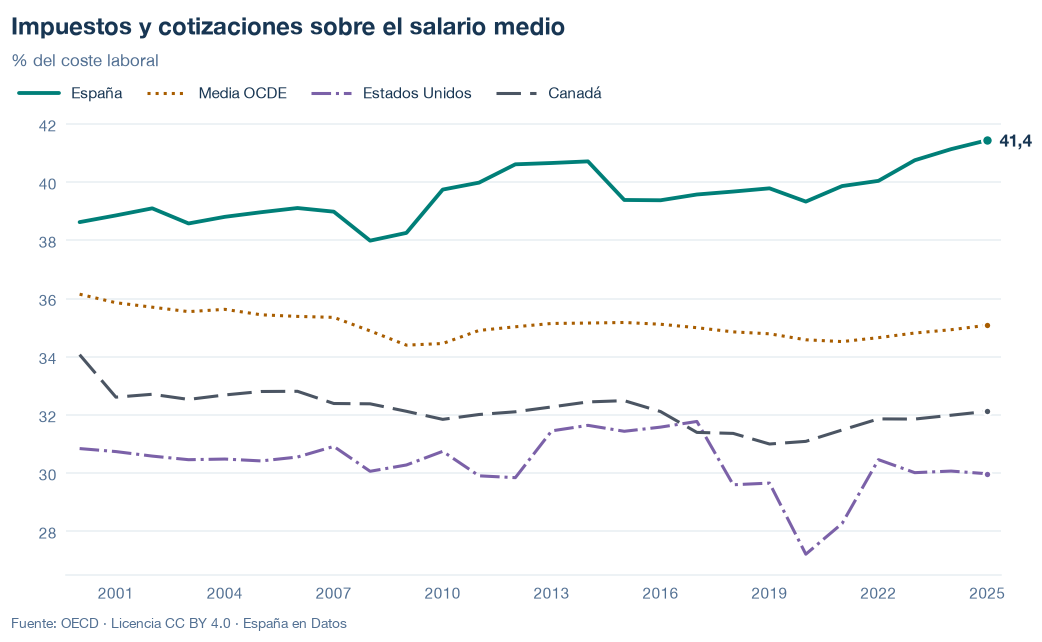

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/cuna-fiscal-trabajo.json y data/cuna-fiscal-trabajo.csv


## 6. Fuentes, notas y licencia

- OCDE, *Taxing Wages* (`OECD.CTP.TPS,DSD_TAX_WAGES_COMP@DF_TW_COMP`, versión 2.1): `AV_TW` (publicada) y `AV_ITR`, `AV_R_EMPEE_SSC` y `AV_R_EMPER_SSC` (comprobaciones).
- Eurostat, `earn_nt_taxwedge` y `earn_nt_net`, consultados para la UE-27 (sin dato comparable).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.